# Accessing CMIP6 Data

**Adapted from** https://github.com/pangeo-gallery/cmip6/blob/master/ECS_Gregory_method.ipynb

---

In this exercise, you'll be familiarizing yourself with the best method for downloading data from Phase 6 of the Coupled Model Intercomparison Project (CMIP6). The text will be covering CMIP6 in more detail in Module 4, but generally data from CMIP6 will be used throughout this module to compare to other data sources and perform similar analysis you'll read about in the text. By the end of this lab you should be comfortable downloading data for these future modules and possibly even your own future research.

In [1]:
### Load the necessary packages ###
from matplotlib import pyplot as plt
import xarray as xr
import numpy as np
import pandas as pd
import dask
from dask.diagnostics import progress
from tqdm.autonotebook import tqdm
import intake
import fsspec
import seaborn as sns
from collections import defaultdict

C:\Users\madel\AppData\Local\Temp\ipykernel_24740\2438674663.py:8: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm


## Data catalogs

This notebook uses [`intake-esm`](https://intake-esm.readthedocs.io/en/latest/) to ingest and organize the climate model output which can be found in google cloud storage here: `https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv`. We can first look at how this data is formatted,

In [2]:
df = pd.read_csv('https://storage.googleapis.com/cmip6/cmip6-zarr-consolidated-stores.csv')
df.head()

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,ps,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
1,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rsds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
2,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlus,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
3,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,rlds,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706
4,HighResMIP,CMCC,CMCC-CM2-HR4,highresSST-present,r1i1p1f1,Amon,psl,gn,gs://cmip6/CMIP6/HighResMIP/CMCC/CMCC-CM2-HR4/...,NaN,20170706


In the header of the csv file we can see all the different ids to identify variables, sources, institutions, forcing, etc.

For example, here we show the various institutions involved in CMIP6 using the `institution_id` column.

In [3]:
# need to print this in a full list
df['institution_id'].unique()

<ArrowStringArray>
[               'CMCC', 'EC-Earth-Consortium',                'MOHC',
               'ECMWF',           'NOAA-GFDL',                'IPSL',
        'E3SM-Project',        'CNRM-CERFACS',           'NASA-GISS',
                 'BCC',               'MIROC',                 'AWI',
                'NCAR',                 'MRI',               'CCCma',
                 'SNU',                 'CAS',                 'INM',
               'NUIST',   'HAMMOZ-Consortium',                'CAMS',
               'MPI-M',                'DKRZ',                 'DWD',
                  'UA',            'NIMS-KMA',                 'NCC',
            'FIO-QLNM',               'KIOST',        'CSIRO-ARCCSS',
               'CSIRO',           'CCCR-IITM',                 'THU',
             'AS-RCEC',                'NERC',             'RUBISCO']
Length: 36, dtype: str


### Use Intake ESM

[Intake-esm](https://intake-esm.readthedocs.io/) is a new package designed to make working with these data archives a bit simpler.

In [4]:
import intake

col = intake.open_esm_datastore("https://storage.googleapis.com/cmip6/pangeo-cmip6.json")
col

,unique
activity_id,18
institution_id,36
source_id,88
experiment_id,170
member_id,657
table_id,37
variable_id,700
grid_label,10
zstore,514818
dcpp_init_year,61


we can see the unique institutions number here matches our unique institutions we just printed. We can also see unique counts of other data included.

### Loading data

[intake-esm](https://intake-esm.readthedocs.io/) enables loading data directly into an [xarray.DataArray](http://xarray.pydata.org/en/stable/api.html#dataset), which is a metadata-aware extension of numpy arrays. This way we have access to well formatted information about the data rather than just floats and abbreviations in the form of unique ids.

Note that data on the cloud are in [zarr](https://zarr.readthedocs.io/en/stable/) format, an extension of the metadata-aware format [netcdf](https://www.unidata.ucar.edu/software/netcdf/) commonly used in geosciences.


In [5]:
first5 = col.df.drop_duplicates("variable_id").head(5)
for var, zstore in zip(first5.variable_id, first5.zstore):
    ds = xr.open_zarr(zstore, consolidated=True, storage_options={"token": "anon"})
    print(f"{var}: {ds[var].attrs['long_name']} ({ds[var].attrs['units']})")


ps: Surface Air Pressure (Pa)
rsds: Surface Downwelling Shortwave Radiation (W m-2)
rlus: Surface Upwelling Longwave Radiation (W m-2)
rlds: Surface Downwelling Longwave Radiation (W m-2)
psl: Sea Level Pressure (Pa)


We can even access long, human readable names within this data using xarray.

## Searching Data with Intake-ESM

Looking back at the full data available to us:

In [6]:
col

,unique
activity_id,18
institution_id,36
source_id,88
experiment_id,170
member_id,657
table_id,37
variable_id,700
grid_label,10
zstore,514818
dcpp_init_year,61


There are a lot of different labels here to look at, but here are some key ones needed when searching for a particular set of data:

- `experiment_id` - the simulation scenario, i.e. what forcing the model was run with. For example
- `variable_id` - the physical quantity being stored, as a short code. We printed a few long name examples of this above.
- `table_id` - the model component (or sphere as we discussed in module 1) and how often the output was saved. For example, `Amon` is monthly atmosphere output or `SIday` is daily sea ice.
- `member_id` - which run of the model this is, when the same experiment was run more than once. It is written `r<k>i<l>p<m>f<n>`: **r**ealization (initial conditions), **i**nitialization method, **p**hysics version, and **f**orcing version. For example, `r1i1p1f1` is the first run, and `r2i1p1f1` is the same setup started from different initial conditions.

You can also find more information on ids and their definitions at the following links: 
+ [CMIP6 Controlled Vocabularies](https://wcrp-cmip.github.io/CMIP6_CVs/)
+ [CMIP6 Data Request browser](https://clipc-services.ceda.ac.uk/dreq/index.html).


#### Choosing and querying data

Say we want to look at the `abrupt-2xCO2` experiment (in which CO2 concentrations are instantaneously doubled from a pre-industrial control state). This is how we could look at that

In [7]:
### Create the data query ###
expts = ['abrupt-2xCO2'] # pick the `abrupt-2xCO2` forcing experiments

query = dict(
    experiment_id=['abrupt-2xCO2'], # pick the `abrupt-2xCO2` forcing experiments
    table_id='Amon',                # choose to look at atmospheric variables (A) saved at monthly resolution (mon)
    variable_id=['tas','pr'], # grab data for near-surface air temperature and precipitation
    member_id = 'r1i1p1f1',                     # pick the r1i1p1f1 initialization (usually seen as the default realization or set of initial conditions)
)

### Grab the data which meets our specifications ###
col_subset = col.search(require_all_on=["source_id"], **query) #Grab subset of CMIP6 data that we need

num_models = len(col_subset.keys()) #the number of keys in the dataset will tell us the number of models
vars_incl = col_subset.df.groupby("source_id")['variable_id'].unique() #this will tell us the variables included for each model  

print('Number of Models: ',num_models)
print('Variables Included:',vars_incl)


Number of Models:  5
Variables Included: source_id
GISS-E2-1-G     [pr, tas]
GISS-E2-1-H     [pr, tas]
IPSL-CM6A-LR    [pr, tas]
MIROC6          [tas, pr]
MRI-ESM2-0      [pr, tas]
Name: variable_id, dtype: object


From this example we can see 5 sources that fit our specifications in CMIP6. This is a very simple example and doesn't seem to have a ton of data for this querey seeing as there are 88 unique source IDs and we only found the 5.

### Download the CMIP6 Data From the Archive

So far, we've only provided our search query, and double checked that all variables are included. Now we are going to store the datasets in a dictionary, and do some preprocessing of the data so standardize it. This includes loading the data into memory using Dask, removing unnecessary dimensions (like 'time_bounds' or 'bounds'), and merging the datasets into a common dataset. 

In [8]:
### Create some necessary functions to pre-process the data ###
def drop_all_bounds(ds): # function which removes dimensions like time_bounds or bounds, which are not needed here 
    """Drop coordinates like 'time_bounds' from datasets,
    which can lead to issues when merging."""
    drop_vars = [vname for vname in ds.coords
                 if (('_bounds') in vname ) or ('_bnds') in vname]
    return ds.drop(drop_vars)

def open_dsets(df): # function which opens zarr dataset and executes the drop_all_bounds() function
    """Open datasets from cloud storage and return xarray dataset."""
    dsets = [xr.open_zarr(fsspec.get_mapper(ds_url, token='anon'), consolidated=True)
             .pipe(drop_all_bounds)
             for ds_url in df.zstore]
    try:
        ds = xr.merge(dsets, join='exact')
        return ds
    except ValueError:
        return None

def open_delayed(df): # function to load dataset into memory using Dask
    """A dask.delayed wrapper around `open_dsets`.
    Allows us to open many datasets in parallel."""
    return dask.delayed(open_dsets)(df)

### Store datasets in dictionary ###
dsets = defaultdict(dict) # store datasets in a dictionary 

### Loop through models and load into memory using Dask ###
for group, df in col_subset.df.groupby(by=['source_id', 'experiment_id']):
    dsets[group[0]][group[1]] = open_delayed(df)

dsets_ = dask.compute(dict(dsets))[0] #up until this point, no computation has been done. It is only here that the data is processed.


C:\Users\madel\AppData\Local\Temp\ipykernel_24740\945188819.py:11: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  dsets = [xr.open_zarr(fsspec.get_mapper(ds_url, token='anon'), consolidated=True)
C:\Users\madel\AppData\Local\Temp\ipykernel_24740\945188819.py:11: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  dsets = [xr.open_zarr(fsspec.get_mapper(ds_url, token='anon'), consolidated=True)
C:\Users\madel\AppData\Local\Temp\ipykernel_24740\945188819.py:7: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  return ds.drop(drop_vars)
C:\Users\ma

### Calculate the Global Mean Values

Now that we've loaded the data from each of the individual models into memory, and stored them in a common dataset, we will next calculate the global mean values for each model and variable combination:

In [9]:
### Create functions to calculate global mean values for each model ###

def get_lat_name(ds): # function to check whether latitude coordinate is 'lat' or 'latitude' as different models may have different names for lat/lon
    for lat_name in ['lat', 'latitude']:
        if lat_name in ds.coords:
            return lat_name
    raise RuntimeError("Couldn't find a latitude coordinate")

def global_mean(ds): # function which calculates the global mean value for each variable in the dataset
    lat = ds[get_lat_name(ds)]
    weight = np.cos(np.deg2rad(lat))
    weight /= weight.mean()
    other_dims = set(ds.dims) - {'time'}
    return (ds * weight).mean(other_dims)

### Calculate global mean values for each of the datasets, and resample to annual means ### 

expt_da = xr.DataArray(expts, dims='experiment_id',
                       coords={'experiment_id': expts}) # create data-array with dimensions and coordinates of experiment_id

print(expt_da)

dsets_aligned = {} # initalize an empty dictionary to store global mean data in

for k, v in tqdm(dsets_.items()): #loop through each model and variable
    expt_dsets = v.values()
    if any([d is None for d in expt_dsets]):
        print(f"Missing experiment for {k}")
        continue

    for ds in expt_dsets:
        ds.coords['year'] = ds.time.dt.year - ds.time.dt.year[0]

    # workaround for
    # https://github.com/pydata/xarray/issues/2237#issuecomment-620961663
    dsets_ann_mean = [v[expt].pipe(global_mean)
                             .swap_dims({'time': 'year'})
                             .drop('time')
                             .coarsen(year=12).mean() #calculate annual mean
                      for expt in expts] #calculate global, annual means for each variable and model

    # add information about experiment_id
    dsets_aligned[k] = xr.concat(dsets_ann_mean, join='right',
                                 dim=expt_da)

with progress.ProgressBar():
    dsets_aligned_ = dask.compute(dsets_aligned)[0] #do the computation using Dask delayed execution

<xarray.DataArray (experiment_id: 1)> Size: 48B
array(['abrupt-2xCO2'], dtype='<U12')
Coordinates:
  * experiment_id  (experiment_id) <U12 48B 'abrupt-2xCO2'


  0%|          | 0/5 [00:00<?, ?it/s]C:\Users\madel\AppData\Local\Temp\ipykernel_24740\4022646539.py:38: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
C:\Users\madel\AppData\Local\Temp\ipykernel_24740\4022646539.py:38: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
C:\Users\madel\AppData\Local\Temp\ipykernel_24740\4022646539.py:38: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
C:\Users\madel\AppData\Local\Temp\ipykernel_24740\4022646539.py:38: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
 80%|████████  | 4/5 [00:00<00:00, 37.45it/s]C:\Users\madel\AppData\Local\Temp\ipykernel_24740\4022646539.py:38: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  .drop('time')
100%|██████████| 5/5 [00:00<00:00, 39.76it/s]


[########################################] | 100% Completed | 497.31 s


### Concatenate Individual Models into One Dataset

The models are currently stored as separate datasets. Let's concatenate the datasets so that all models are included in one dataset, with a new dimension, 'source_id' (the 'model' dimension). Take a look at the final dataset you created:

In [10]:
source_ids = list(dsets_aligned_.keys())
source_da = xr.DataArray(source_ids, dims='source_id',
                         coords={'source_id': source_ids})

big_ds = xr.concat([ds.reset_coords(drop=True)
                    for ds in dsets_aligned_.values()],
                   dim=source_da)
big_ds

C:\Users\madel\AppData\Local\Temp\ipykernel_24740\3697643718.py:5: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'year' ('year',) The recommendation is to set join explicitly for this case.
  big_ds = xr.concat([ds.reset_coords(drop=True)


<xarray.Dataset> Size: 22kB
Dimensions:        (source_id: 5, experiment_id: 1, year: 250)
Coordinates:
  * source_id      (source_id) <U12 240B 'GISS-E2-1-G' ... 'MRI-ESM2-0'
  * experiment_id  (experiment_id) <U12 48B 'abrupt-2xCO2'
  * year           (year) float64 2kB 0.0 1.0 2.0 3.0 ... 247.0 248.0 249.0
Data variables:
    pr             (source_id, experiment_id, year) float64 10kB 3.386e-05 .....
    tas            (source_id, experiment_id, year) float64 10kB 287.5 ... nan
Attributes: (12/54)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CFMIP
    branch_method:          standard
    branch_time_in_child:   0.0
    branch_time_in_parent:  0.0
    cmor_version:           3.3.2
    ...                     ...
    status:                 2019-11-01;created;by nhn2@columbia.edu
    axis:                   Y
    bounds:                 lat_bnds
    long_name:              latitude
    standard_name:          latitude
    units:                  degrees_north

We can also quickly plot our two variables to check our download

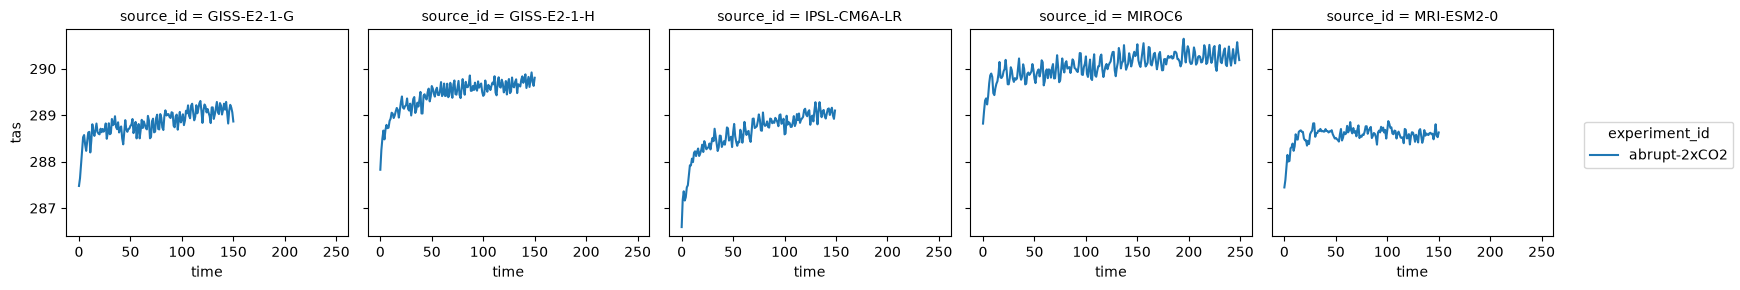

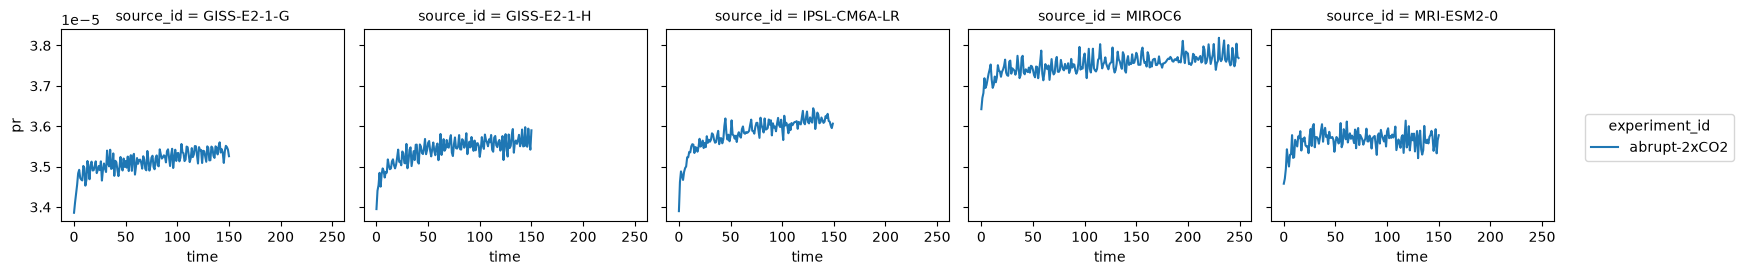

In [12]:
big_ds.tas.plot.line(col='source_id', x='year', col_wrap=5)
big_ds.pr.plot.line(col='source_id', x='year', col_wrap=5)

Now that this data has been downloaded we can save it as a netcdf file to be used later. This prevents the need for running the downloading process again, which can get very tedious and long, especially when looking at large datasets.

In [ ]:
big_ds.to_netcdf('abrupt-4xCO2_global_annual_means.nc')
